# Studio Proyek 3 Fine-Tuning Transformer Pretrained untuk NLP
##Kelompok 13
**Anggota:**

1 Najlatika 123140078

 2 Hanifah Hasanah 123140082

 3 Muhammad Piela Nugraha 123140200

---

## 1. Rancangan Eksperimen

### 1.1 Tujuan, Dataset, dan Pembagian Data
Tujuan: membandingkan tiga backbone dan tiga strategi fine-tuning pada klasifikasi sentimen tiga kelas (*negative*, *neutral*, *positive*), lalu merekomendasikan satu kombinasi berdasarkan bukti angka.

Dataset: **SmSA** (IndoNLU; Wilie dkk., 2020), opsi yang disarankan soal. Teksnya berbahasa Indonesia sehingga backbone monolingual dapat diuji langsung.

| Bagian | Ukuran | Peran |
| :--- | :---: | :--- |
| Latih | 5.000 (subset berstrata dari 10.933 data bersih) | melatih model; dalam rentang soal (3.000–6.000) |
| Validasi | 1.246 (bersih) | **hanya** memilih epoch terbaik |
| Uji resmi | 500 | dipakai seluruhnya; disentuh **sekali** per run |

Alasan ukuran subset: 5.000 berada di tengah rentang yang diizinkan, dan 27 run selesai dalam satu sesi GPU T4. Subset dipilih sekali (`seed = 42`, berstrata) dan sama untuk semua run.

### 1.2 Matriks Eksperimen (3 Backbone x 3 Strategi x 3 Seed = 27 Run)

| Backbone | Arsitektur | Full Fine-Tuning | Partial Freezing | Linear Probing |
| :--- | :--- | :---: | :---: | :---: |
| `bert-base-multilingual-cased` (mBERT) | multibahasa, 12 lapis | 3 seed | 3 seed | 3 seed |
| `distilbert-base-multilingual-cased` | multibahasa terdistilasi, 6 lapis | 3 seed | 3 seed | 3 seed |
| `indobenchmark/indobert-base-p1` (IndoBERT) | monolingual Indonesia, 12 lapis | 3 seed | 3 seed | 3 seed |

*Head replacement* dilakukan pada semua run: head klasifikasi diganti `Dropout(0,1) → Linear(768, 3)` di atas representasi `[CLS]`, identik untuk ketiga backbone (alasan di bagian 4).

### 1.3 Variabel yang Dikunci

| Variabel | Nilai | Alasan |
| :--- | :--- | :--- |
| `max_length` | 128 token | persentil ke-95 panjang token ≤ 103 pada ketiga tokenizer (bagian 3) |
| `batch_size` (latih) | 32 | sama untuk semua run |
| `epochs` | 5; bobot epoch dengan F1 makro validasi tertinggi dipakai untuk uji | anggaran langkah latih seragam; validasi hanya memilih epoch |
| `seeds` | 42, 123, 2024 | sama di semua run; hasil dilaporkan sebagai mean ± SD |
| Learning rate | full dan partial `2e-5`; probing `2e-3` | probing hanya melatih head sehingga butuh LR lebih besar |
| Partial freezing | embedding + 50% lapis awal dibekukan | 6 dari 12 lapis (mBERT, IndoBERT); 3 dari 6 lapis (DistilBERT) |
| Optimizer | AdamW (`wd = 0,01`), warmup linear 10%, peluruhan linear | stabilitas fine-tuning (Mosbach dkk., 2021) |
| Stabilitas numerik | gradient clipping 1,0; FP16 AMP bila CUDA tersedia | |
| Metrik utama | akurasi, F1 makro, F1 per kelas | F1 makro adil untuk kelas minoritas `neutral` |
| Metrik efisiensi | waktu latih, latensi inferensi (`batch = 1`), VRAM puncak, jumlah parameter | protokol FastFormers (Kim & Awadalla, 2020) |


### 1.4 Pertanyaan Riset dan Hipotesis
* **Q1:** backbone mana yang memberi trade-off akurasi–efisiensi terbaik?
* **Q2:** apakah strategi hemat komputasi (partial/probing) cukup kompetitif dibanding full fine-tuning, dengan selisih dibandingkan simpangan antar-seed?
* **Q3:** kombinasi apa yang direkomendasikan, dan mengapa?
* **H1:** IndoBERT menghasilkan F1 makro tertinggi karena dilatih pada korpus Indonesia (`Indo4B`).
* **H2:** urutan performa *full* > *partial* > *probing*; penurunan pada probing lebih kecil untuk IndoBERT daripada backbone multibahasa (Peters dkk., 2019).
* **H3:** DistilBERT memangkas waktu latih, latensi, dan memori dengan penurunan F1 yang moderat (Sanh dkk., 2019).

### 1.5 Pembanding dan Kriteria Rekomendasi
* **Pembanding:** tebakan acak (F1 makro ≈ 0,33), baseline TF-IDF + Logistic Regression (bagian 3), dan simpangan antar-seed.
* **Kriteria Q3:** (1) F1 makro uji harus melampaui TF-IDF latih penuh; (2) selisih F1 yang lebih kecil dari simpangan antar-seed dianggap setara; (3) di antara kandidat yang setara, pilih waktu latih dan VRAM terendah (anggaran komputasi), lalu latensi terukur terendah; (4) keterjelasan: setiap klaim harus didukung angka mean ± SD dari 3 seed.

In [ ]:
import os
import gc
import time
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoConfig,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
    set_seed,
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

# konfigurasi utama eksperimen yang dikunci
CONFIG = {
    "max_length": 128,
    "batch_size": 32,
    "epochs": 5,
    "n_train": 5000,
    "subset_seed": 42,
    "seeds": [42, 123, 2024],
    "lr": {"full": 2e-5, "partial": 2e-5, "probing": 2e-3},
    "weight_decay": 0.01,
    "warmup_ratio": 0.10,
    "max_grad_norm": 1.0,
    "dropout": 0.1,
    "eval_test": True,
    "output_dir": "hasil_eksperimen_smsa",
}

BACKBONES = {
    "bert-mbert": "bert-base-multilingual-cased",
    "distilbert": "distilbert-base-multilingual-cased",
    "indobert": "indobenchmark/indobert-base-p1",
}

STRATEGIES = ["full", "partial", "probing"]
LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
NUM_LABELS = len(LABEL2ID)

os.makedirs(CONFIG["output_dir"], exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_FP16 = torch.cuda.is_available()

print("device:", DEVICE, "| gpu:", torch.cuda.get_device_name(0) if USE_FP16 else "cpu")

def seed_everything(seed):
    # mengunci seluruh sumber keacakan demi reproduksibilitas
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    set_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

device: cuda | gpu: Tesla T4


## 2. Landasan Teori dan Pemetaan Literatur

 No | Rujukan | Temuan utama | Keputusan desain |
| :-: | :--- | :--- | :--- |
| 1 | Wilie dkk. (2020), IndoNLU | benchmark SmSA dan model IndoBERT (korpus `Indo4B`); IndoBERT-base unggul atas mBERT pada SmSA (F1 uji 87,73% vs 84,14%) | memilih SmSA; IndoBERT dan mBERT sebagai backbone; H1 |
| 2 | Sanh dkk. (2019), DistilBERT | 6 lapis, ±40% lebih kecil, ±60% lebih cepat, mempertahankan ±97% kemampuan BERT | DistilBERT sebagai backbone efisien; H3 |
| 3 | Peters dkk. (2019) | *feature extraction* dapat mendekati fine-tuning bila representasi pra-latih sesuai tugas | membandingkan probing dan partial dengan full; H2 |
| 4 | Ben-Zaken dkk. (2022), BitFit | melatih sedikit parameter memerlukan LR lebih besar | LR probing `2e-3`, LR full/partial `2e-5` |
| 5 | Mosbach dkk. (2021); Zhang dkk. (2021) | fine-tuning BERT tidak stabil tanpa *bias correction* dan warmup; hasil perlu dilaporkan lintas seed | AdamW, warmup 10%, `wd = 0,01`, clipping 1,0; 3 seed, mean ± SD |
| 6 | Kim & Awadalla (2020), FastFormers | protokol latensi: `batch = 1`, warm-up, sinkronisasi GPU | pengukuran latensi (bagian 5.2) |

*Catatan:* pada paper IndoNLU mBERT bertipe *uncased*, sedangkan eksperimen ini memakai *cased*. Ukuran kosakata IndoBERT hasil audit checkpoint adalah 50.000 (paper menyebut 30.522).

## 3. Pemuatan, Pembersihan, dan Eksplorasi Data (EDA)

Data dimuat dari repositori resmi IndoNLU (`smsa_doc-sentiment-prosa`). Tiga langkah dilakukan untuk mencegah kebocoran data dan label ambigu:
1. **Konflik label** pada data latih (teks sama, label berbeda): 0 ditemukan.
2. **Duplikat data latih** dibuang: 11.000 → 10.933 (67 duplikat).
3. **Duplikat validasi** dan kalimat validasi yang muncul di data latih dibuang: 1.260 → 1.246 (14 kalimat).

Data uji resmi (500 kalimat berlabel) diperiksa tidak beririsan dengan data latih maupun validasi (`assert` pada kode).

### 3.1 Distribusi Kelas

| Bagian | Positive | Negative | Neutral |
| :--- | :---: | :---: | :---: |
| Latih bersih (10.933) | 6.383 | 3.412 | 1.138 |
| Subset latih (5.000) | 2.919 | 1.560 | 521 (10,4%) |
| Validasi (1.246) | 728 | 389 | 129 (10,4%) |
| Uji resmi (500) | 208 | 204 | 88 (17,6%) |

Kelas `neutral` minoritas dan proporsinya di data uji berbeda dari data latih (sesuai catatan soal). Karena itu **F1 makro** dipakai sebagai metrik utama.

### 3.2 Panjang Sekuens
Persentil ke-95 panjang token adalah 103 (mBERT dan DistilBERT) dan 79 (IndoBERT); hanya 0,2% kalimat melebihi 128 token pada mBERT/DistilBERT. `max_length = 128` memadai.

### 3.3 Baseline TF-IDF
TF-IDF (unigram + bigram) + Logistic Regression; nilai `C` (1 atau 10) dipilih dari F1 makro validasi. F1 makro uji: **0,750** (latih penuh) dan 0,678 (subset 5.000). Pembanding utama adalah latih penuh (0,750), sejalan dengan acuan soal (≈ 0,73).

In [ ]:
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa"
LOCAL_DIR = "indonlu-master/dataset/smsa_doc-sentiment-prosa"

def load_split(fname):
    # memuat file tsv dari lokal jika tersedia atau unduh dari github indonlu
    local_path = os.path.join(LOCAL_DIR, fname)
    src = local_path if os.path.exists(local_path) else f"{BASE_URL}/{fname}"
    df = pd.read_csv(src, sep="\t", header=None, names=["text", "label"])
    df["text"] = df["text"].astype(str).str.strip()
    df["label"] = df["label"].astype(str).str.strip()
    return df

train_raw = load_split("train_preprocess.tsv")
valid_raw = load_split("valid_preprocess.tsv")

# membuang teks dengan label bertentangan di data latih
label_per_text = train_raw.groupby("text")["label"].nunique()
conflict_texts = set(label_per_text[label_per_text > 1].index)
train = train_raw[~train_raw["text"].isin(conflict_texts)].drop_duplicates("text").reset_index(drop=True)

# membuang duplikat validasi dan teks validasi yang bocor ke data latih
valid = valid_raw.drop_duplicates("text")
valid = valid[~valid["text"].isin(set(train["text"]))].reset_index(drop=True)

train["label_id"] = train["label"].map(LABEL2ID)
valid["label_id"] = valid["label"].map(LABEL2ID)
assert train["label_id"].notna().all() and valid["label_id"].notna().all()

print(f"train bersih: {len(train_raw)} -> {len(train)} (konflik={len(conflict_texts)})")
print(f"valid bersih: {len(valid_raw)} -> {len(valid)}")
print("distribusi train:", train["label"].value_counts().to_dict())
print("distribusi valid:", valid["label"].value_counts().to_dict())

# subset data latih sesuai ketentuan studio (3.000-6.000 sampel), stratifikasi kelas, dikunci dengan seed tersendiri
from sklearn.model_selection import train_test_split
train_full = train.copy()    # data latih bersih penuh (hanya dipakai untuk baseline TF-IDF rujukan)
train, _ = train_test_split(
    train_full,
    train_size=CONFIG["n_train"],
    stratify=train_full["label_id"],
    random_state=CONFIG["subset_seed"],
)
train = train.reset_index(drop=True)
assert 3000 <= len(train) <= 6000, "ukuran subset latih di luar 3.000-6.000"
print(f"subset latih: {len(train_full)} -> {len(train)} | distribusi:", train["label"].value_counts().to_dict())

# data uji resmi SmSA (500 kalimat berlabel): hanya disentuh sekali per run
test_raw = load_split("test_preprocess.tsv")
test_df = test_raw[test_raw["label"].isin(LABEL2ID)].reset_index(drop=True)
test_df["label_id"] = test_df["label"].map(LABEL2ID)
assert len(test_df) == 500, "data uji resmi harus 500 kalimat"
assert not set(test_df["text"]) & (set(train_full["text"]) | set(valid["text"])), "data uji bocor ke latih/validasi"
print(f"uji resmi: {len(test_df)} | distribusi:", test_df["label"].value_counts().to_dict())

# audit ukuran kosakata dan distribusi panjang token tiap backbone
_tok_cache = {}
def get_tokenizer(backbone_key):
    if backbone_key not in _tok_cache:
        _tok_cache[backbone_key] = AutoTokenizer.from_pretrained(BACKBONES[backbone_key])
    return _tok_cache[backbone_key]

eda_rows = []
for key, model_name in BACKBONES.items():
    tok = get_tokenizer(key)
    cfg = AutoConfig.from_pretrained(model_name)
    lens = [len(ids) for ids in tok(list(train["text"]), truncation=False)["input_ids"]]
    eda_rows.append({
        "backbone": key,
        "vocab_size_aktual": cfg.vocab_size,
        "token_median": int(np.median(lens)),
        "token_p95": int(np.percentile(lens, 95)),
        "persen_lebih_128": round(float(np.mean(np.array(lens) > CONFIG["max_length"]) * 100), 2),
    })

eda_df = pd.DataFrame(eda_rows)
display(eda_df)

train bersih: 11000 -> 10933 (konflik=0)
valid bersih: 1260 -> 1246
distribusi train: {'positive': 6383, 'negative': 3412, 'neutral': 1138}
distribusi valid: {'positive': 728, 'negative': 389, 'neutral': 129}
subset latih: 10933 -> 5000 | distribusi: {'positive': 2919, 'negative': 1560, 'neutral': 521}
uji resmi: 500 | distribusi: {'positive': 208, 'negative': 204, 'neutral': 88}


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,backbone,vocab_size_aktual,token_median,token_p95,persen_lebih_128
0,bert-mbert,119547,44,103,0.2
1,distilbert,119547,44,103,0.2
2,indobert,50000,33,79,0.0


Data latih bersih berjumlah 10.933 kalimat setelah 67 duplikat dihapus, sedangkan validasi berjumlah 1.246 kalimat. Tidak ditemukan konflik label. Sebanyak 5.000 data latih dipilih secara berstrata. Kelas neutral mencakup 10,4% data latih, tetapi 17,6% data uji. Karena proporsinya berbeda, F1 makro digunakan agar performa setiap kelas tetap diperhitungkan. Pemeriksaan juga memastikan tidak ada data uji yang masuk ke data latih atau validasi

mBERT dan DistilBERT memiliki kosakata 119.547, sedangkan IndoBERT 50.000. Panjang token median IndoBERT lebih pendek (33 token) dibandingkan mBERT dan DistilBERT (44 token). Persentil ke-95 seluruh tokenizer masih di bawah 128 token. Karena itu, `max_length = 128` dinilai cukup untuk menampung hampir seluruh kalimat

In [ ]:
# baseline TF-IDF + Logistic Regression (pembanding non-neural; nilai C dipilih dari F1 validasi, bukan dari data uji)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

def tfidf_baseline(train_part, nama):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X_tr = vec.fit_transform(train_part["text"])
    X_va, X_te = vec.transform(valid["text"]), vec.transform(test_df["text"])
    best = None
    for C in (1, 10):
        clf = LogisticRegression(C=C, max_iter=2000).fit(X_tr, train_part["label_id"])
        f1_val = f1_score(valid["label_id"], clf.predict(X_va), average="macro")
        if best is None or f1_val > best[0]:
            best = (f1_val, C, clf)
    f1_val, C, clf = best
    pred = clf.predict(X_te)
    return {
        "baseline": nama, "n_train": len(train_part), "C": C,
        "val_macro_f1": round(f1_val, 4),
        "test_accuracy": round(accuracy_score(test_df["label_id"], pred), 4),
        "test_macro_f1": round(f1_score(test_df["label_id"], pred, average="macro"), 4),
    }

baseline_df = pd.DataFrame([
    tfidf_baseline(train, f"TF-IDF + LR (subset {len(train)})"),
    tfidf_baseline(train_full, f"TF-IDF + LR (latih penuh {len(train_full)})"),
])
baseline_df.to_csv(os.path.join(CONFIG["output_dir"], "baseline_tfidf.csv"), index=False)
display(baseline_df)
print("Tebakan acak 3 kelas: F1 makro ≈ 0.33")

,baseline,n_train,C,val_macro_f1,test_accuracy,test_macro_f1
0,TF-IDF + LR (subset 5000),5000,10,0.8282,0.75,0.6779
1,TF-IDF + LR (latih penuh 10933),10933,10,0.8438,0.81,0.7500


Tebakan acak 3 kelas: F1 makro ≈ 0.33


F1 makro TF-IDF + Logistic Regression mencapai 0,678 pada subset 5.000 data dan 0,750 pada seluruh data latih. Hasil ini menunjukkan bahwa jumlah data berpengaruh terhadap performa baseline. Nilai 0,750 digunakan sebagai pembanding utama, sedangkan tebakan acak berada di sekitar 0,33.

## 4. Arsitektur Classification Head Seragam dan Strategi
### 4.1 Head replacement (`UniformSentimentClassifier`)
Head bawaan HuggingFace berbeda antar-backbone. Contohnya `DistilBertForSequenceClassification` menambah lapis `pre_classifier` (768→768), sehingga linear probing melatih 592.899 parameter, 257 kali lebih banyak daripada head linear 2.307 parameter. Agar perbandingan adil, semua backbone dibungkus kelas yang sama: representasi `[CLS]` lapis terakhir (`last_hidden_state[:, 0, :]`) → `Dropout(0,1)` → `Linear(768, 3)` (head baru; jumlah keluaran = jumlah label). *Pooler* BERT/IndoBERT dimatikan (`add_pooling_layer=False`) agar tidak ada parameter menganggur.

### 4.2 Strategi dan Parameter Terlatih
Kode pembekuan lapis ada pada fungsi `apply_strategy`; hasil audit parameter ditampilkan di bawah sel kode.

| Strategi | Yang dilatih | mBERT | DistilBERT | IndoBERT |
| :--- | :--- | :---: | :---: | :---: |
| `full` | semua parameter | 177,3 jt (100%) | 134,7 jt (100%) | 123,9 jt (100%) |
| `partial` | 50% lapis atas + head (embedding dan 50% lapis bawah beku) | 42,5 jt (24,0%) | 21,3 jt (15,8%) | 42,5 jt (34,3%) |
| `probing` | hanya head linear | 2.307 | 2.307 | 2.307 |

In [ ]:
class SmSADataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.enc = tokenizer(list(texts), truncation=True, max_length=max_length)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item["labels"] = self.labels[idx]
        return item

def make_loaders(backbone_key, seed):
    # membuat dataloader latih ber-seed dan dataloader validasi deterministik
    tok = get_tokenizer(backbone_key)
    collator = DataCollatorWithPadding(tok)
    ds_tr = SmSADataset(train["text"], train["label_id"], tok, CONFIG["max_length"])
    ds_va = SmSADataset(valid["text"], valid["label_id"], tok, CONFIG["max_length"])
    gen = torch.Generator()
    gen.manual_seed(seed)
    dl_tr = DataLoader(
        ds_tr,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        collate_fn=collator,
        generator=gen,
    )
    dl_va = DataLoader(ds_va, batch_size=64, shuffle=False, collate_fn=collator)
    dl_te = None
    if CONFIG["eval_test"] and test_df is not None:
        ds_te = SmSADataset(test_df["text"], test_df["label_id"], tok, CONFIG["max_length"])
        dl_te = DataLoader(ds_te, batch_size=64, shuffle=False, collate_fn=collator)
    return dl_tr, dl_va, dl_te

class UniformSentimentClassifier(nn.Module):
    def __init__(self, model_name, num_labels=3, dropout_prob=0.1):
        super().__init__()
        if "distilbert" in model_name.lower():
            self.backbone = AutoModel.from_pretrained(model_name)
        else:
            # nonaktifkan pooler agar tidak ada parameter tidak terpakai
            self.backbone = AutoModel.from_pretrained(model_name, add_pooling_layer=False)
        hidden_size = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout_prob)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None):
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None and "distilbert" not in self.backbone.config.model_type:
            kwargs["token_type_ids"] = token_type_ids
        outputs = self.backbone(**kwargs)
        cls_repr = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(self.dropout(cls_repr))
        return logits

def get_encoder_layers(model):
    base = model.backbone
    return base.encoder.layer if hasattr(base, "encoder") else base.transformer.layer

def apply_strategy(model, strategy):
    # mengatur status pembekuan gradien sesuai strategi adaptasi
    for p in model.parameters():
        p.requires_grad = True
    if strategy == "full":
        pass
    elif strategy == "partial":
        layers = get_encoder_layers(model)
        n_freeze = len(layers) // 2
        for p in model.backbone.embeddings.parameters():
            p.requires_grad = False
        for layer in layers[:n_freeze]:
            for p in layer.parameters():
                p.requires_grad = False
    elif strategy == "probing":
        for p in model.backbone.parameters():
            p.requires_grad = False
    else:
        raise ValueError(f"strategi tidak dikenal: {strategy}")
    return model

def build_model(backbone_key, strategy, seed):
    seed_everything(seed)
    model = UniformSentimentClassifier(
        BACKBONES[backbone_key],
        num_labels=NUM_LABELS,
        dropout_prob=CONFIG["dropout"],
    )
    model = apply_strategy(model, strategy)
    return model.to(DEVICE)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

# audit parameter seluruh kombinasi backbone dan strategi
param_audit = []
for b_key in BACKBONES:
    for strat in STRATEGIES:
        m = build_model(b_key, strat, seed=42)
        layers = get_encoder_layers(m)
        frozen_l = sum(all(not p.requires_grad for p in l.parameters()) for l in layers)
        tot_p, trn_p = count_params(m)
        param_audit.append({
            "backbone": b_key,
            "strategy": strat,
            "total_params": tot_p,
            "trainable_params": trn_p,
            "persen_terlatih": round(trn_p / tot_p * 100, 4),
            "lapis_beku": f"{frozen_l}/{len(layers)}",
        })
        del m
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

param_audit_df = pd.DataFrame(param_audit)
display(param_audit_df)
assert (param_audit_df[param_audit_df["strategy"] == "probing"]["trainable_params"] == 2307).all()
for b in BACKBONES:
    t = param_audit_df[param_audit_df.backbone == b].set_index("strategy")["trainable_params"]
    assert t["probing"] < t["partial"] < t["full"], f"urutan salah: {b}"
print("OK: probing < partial < full di semua backbone")

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (18 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: indobenchmark/indobert-base-p1
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,backbone,strategy,total_params,trainable_params,persen_terlatih,lapis_beku
0,bert-mbert,full,177265155,177265155,100.0000,0/12
1,bert-mbert,partial,177265155,42529539,23.9920,6/12
2,bert-mbert,probing,177265155,2307,0.0013,12/12
3,distilbert,full,134736387,134736387,100.0000,0/6
4,distilbert,partial,134736387,21265923,15.7834,3/6
5,distilbert,probing,134736387,2307,0.0017,6/6
6,indobert,full,123853059,123853059,100.0000,0/12
7,indobert,partial,123853059,42529539,34.3387,6/12
8,indobert,probing,123853059,2307,0.0019,12/12


OK: probing < partial < full di semua backbone


Jumlah parameter yang dilatih semakin sedikit dari strategi full, partial, hingga probing. Pada partial, mBERT dan IndoBERT melatih sekitar 42,5 juta parameter, sedangkan DistilBERT melatih 21,3 juta parameter. Pada probing, ketiga backbone hanya melatih 2.307 parameter pada bagian klasifikasi. Hasil audit menunjukkan jumlah lapis yang dibekukan sudah sesuai dengan rancangan eksperimen.

## 5. Protokol Pelatihan dan Pengukuran
### 5.1 Pelatihan dan Seleksi Epoch
* **Optimasi:** AdamW (*bias correction* aktif), *weight decay* 0,01 (tidak untuk bias dan LayerNorm), warmup linear 10% lalu peluruhan linear, *gradient clipping* 1,0 (Mosbach dkk., 2021).
* **Epoch:** setiap run berjalan 5 epoch. Setelah tiap epoch model dievaluasi pada data validasi, dan bobot dengan F1 makro validasi tertinggi dipulihkan. Data validasi hanya dipakai untuk memilih epoch.
* **Evaluasi akhir:** model terpilih dievaluasi pada data uji resmi satu kali per run. Seluruh metrik utama di laporan ini adalah metrik **uji**, dilaporkan sebagai mean ± SD dari 3 seed.

### 5.2 Pengukuran Efisiensi (mengacu FastFormers)
* **Waktu latih:** hanya loop latih (maju-mundur dan pembaruan bobot); evaluasi validasi tidak dihitung.
* **VRAM puncak:** `torch.cuda.max_memory_allocated()` yang direset sebelum epoch pertama.
* **Latensi inferensi:** `batch = 1`, FP32, 20 iterasi warm-up, sinkronisasi GPU, 200 kalimat validasi; waktu tokenisasi dipisahkan. Nilainya berisik antar-run, sehingga hanya dipakai untuk membandingkan backbone, bukan strategi pada backbone yang sama.

In [ ]:
criterion = nn.CrossEntropyLoss()

def evaluate_predictions(model, dataloader):
    # menghitung akurasi, f1 makro, dan f1 per kelas pada dataloader
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            labels = batch["labels"].to(DEVICE)
            inputs = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
            with torch.cuda.amp.autocast(enabled=USE_FP16):
                logits = model(**inputs)
                loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            preds = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    prec, rec, macro_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )
    _, _, per_class_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, labels=[0, 1, 2], average=None, zero_division=0
    )
    cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2])
    return {
        "loss": total_loss / len(all_labels),
        "accuracy": float(acc),
        "macro_precision": float(prec),
        "macro_recall": float(rec),
        "macro_f1": float(macro_f1),
        "f1_negative": float(per_class_f1[0]),
        "f1_neutral": float(per_class_f1[1]),
        "f1_positive": float(per_class_f1[2]),
        "confusion_matrix": cm.tolist(),
    }

def benchmark_inference_latency(model, backbone_key, n_samples=200, n_warmup=20):
    # mengukur latensi murni forward pass batch=1 sesuai protokol fastformers
    model.eval()
    tok = get_tokenizer(backbone_key)
    sample_texts = list(valid["text"].iloc[:n_samples])
    encoded_list = [
        tok(t, truncation=True, max_length=CONFIG["max_length"], return_tensors="pt")
        for t in sample_texts
    ]
    encoded_list = [{k: v.to(DEVICE) for k, v in item.items()} for item in encoded_list]

    if USE_FP16:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for i in range(n_warmup):
            _ = model(**encoded_list[i % len(encoded_list)])
        if USE_FP16:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for item in encoded_list:
            _ = model(**item)
        if USE_FP16:
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - t0

    peak_infer_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2) if USE_FP16 else 0.0
    )
    return {
        "infer_ms_per_sent": float(elapsed / n_samples * 1000.0),
        "throughput_sent_per_sec": float(n_samples / elapsed),
        "peak_infer_mem_mb": float(peak_infer_mb),
    }

def build_optimizer_and_scheduler(model, lr, total_steps):
    # memisahkan parameter tanpa weight decay pada bias dan layernorm
    no_decay = ("bias", "LayerNorm.weight", "LayerNorm.bias")
    grouped_params = [
        {
            "params": [
                p for n, p in model.named_parameters()
                if p.requires_grad and not any(nd in n for nd in no_decay)
            ],
            "weight_decay": CONFIG["weight_decay"],
        },
        {
            "params": [
                p for n, p in model.named_parameters()
                if p.requires_grad and any(nd in n for nd in no_decay)
            ],
            "weight_decay": 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(grouped_params, lr=lr)
    warmup_steps = int(CONFIG["warmup_ratio"] * total_steps)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
    )
    return optimizer, scheduler

def train_one_run(backbone_key, strategy, seed, epochs=None, verbose=True):
    epochs = epochs or CONFIG["epochs"]
    lr = CONFIG["lr"][strategy]
    seed_everything(seed)

    dl_tr, dl_va, dl_te = make_loaders(backbone_key, seed)
    model = build_model(backbone_key, strategy, seed)
    total_params, trainable_params = count_params(model)

    total_steps = len(dl_tr) * epochs
    optimizer, scheduler = build_optimizer_and_scheduler(model, lr, total_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_FP16)

    if USE_FP16:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    epoch_records = []
    train_time_sec = 0.0
    best_val_f1, best_epoch, best_state = -1.0, 0, None   # pemilihan epoch terbaik lewat validasi

    for ep in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        ep_start = time.perf_counter()
        for batch in dl_tr:
            labels = batch["labels"].to(DEVICE)
            inputs = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=USE_FP16):
                logits = model(**inputs)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += loss.item()

        if USE_FP16:
            torch.cuda.synchronize()
        train_time_sec += time.perf_counter() - ep_start   # waktu berhenti dihitung di sini

        train_loss = running_loss / len(dl_tr)
        val_m = evaluate_predictions(model, dl_va)          # evaluasi di luar hitungan waktu
        epoch_records.append({
            "backbone": backbone_key,
            "strategy": strategy,
            "seed": seed,
            "epoch": ep,
            "train_loss": round(train_loss, 4),
            "val_loss": round(val_m["loss"], 4),
            "val_accuracy": round(val_m["accuracy"], 4),
            "val_macro_f1": round(val_m["macro_f1"], 4),
            "val_f1_neutral": round(val_m["f1_neutral"], 4),
        })
        if val_m["macro_f1"] > best_val_f1:                 # simpan bobot epoch terbaik (berdasar F1 makro validasi)
            best_val_f1, best_epoch = val_m["macro_f1"], ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(
                f"[{backbone_key} | {strategy} | seed={seed}] "
                f"ep {ep}/{epochs} | tr_loss={train_loss:.4f} | "
                f"val_acc={val_m['accuracy']:.4f} | val_f1={val_m['macro_f1']:.4f}"
            )

    peak_train_mem_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2) if USE_FP16 else 0.0
    )

    model.load_state_dict(best_state)      # kembali ke bobot epoch dengan F1 validasi terbaik
    del best_state
    assert dl_te is not None, "data uji belum dimuat (CONFIG['eval_test'] harus True)"
    final_val = evaluate_predictions(model, dl_va)
    lat_metrics = benchmark_inference_latency(model, backbone_key)
    final_test = evaluate_predictions(model, dl_te)   # data uji resmi: disentuh SEKALI per run

    run_summary = {
        "backbone": backbone_key,
        "strategy": strategy,
        "seed": seed,
        "epochs": epochs,
        "best_epoch": best_epoch,
        "n_train": len(train),
        "lr": lr,
        "total_params": total_params,
        "trainable_params": trainable_params,
        "val_accuracy": final_val["accuracy"],
        "val_macro_precision": final_val["macro_precision"],
        "val_macro_recall": final_val["macro_recall"],
        "val_macro_f1": final_val["macro_f1"],
        "val_f1_negative": final_val["f1_negative"],
        "val_f1_neutral": final_val["f1_neutral"],
        "val_f1_positive": final_val["f1_positive"],
        "test_accuracy": final_test["accuracy"],
        "test_macro_precision": final_test["macro_precision"],
        "test_macro_recall": final_test["macro_recall"],
        "test_macro_f1": final_test["macro_f1"],
        "test_f1_negative": final_test["f1_negative"],
        "test_f1_neutral": final_test["f1_neutral"],
        "test_f1_positive": final_test["f1_positive"],
        "train_time_sec": train_time_sec,
        "peak_train_mem_mb": peak_train_mem_mb,
        "infer_ms_per_sent": lat_metrics["infer_ms_per_sent"],
        "throughput_sent_per_sec": lat_metrics["throughput_sent_per_sec"],
        "peak_infer_mem_mb": lat_metrics["peak_infer_mem_mb"],
        "test_confusion_matrix": str(final_test["confusion_matrix"]),
    }

    del model, optimizer, scheduler, scaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return run_summary, epoch_records

# 6. Eksekusi Matriks Eksperimen (27 Run)

Sel berikut menjalankan 3 backbone × 3 strategi × 3 seed dengan *checkpoint* CSV: setiap run yang selesai langsung ditambahkan ke `hasil_smsa_<kode>.csv` (log per epoch ke `log_per_epoch.csv`). `<kode>` dihitung otomatis dari konfigurasi. Bila sesi terputus, menjalankan ulang sel ini melewati run yang sudah tersimpan.

In [ ]:
import hashlib, json
RUN_CODE = hashlib.md5(json.dumps({"config": CONFIG, "backbones": BACKBONES}, sort_keys=True).encode()).hexdigest()[:6]
RESULTS_CSV = os.path.join(CONFIG["output_dir"], f"hasil_smsa_{RUN_CODE}.csv")
EPOCHS_CSV  = os.path.join(CONFIG["output_dir"], "log_per_epoch.csv")
# memuat progres sebelumnya jika file sudah ada
if os.path.exists(RESULTS_CSV):
    existing_runs_df = pd.read_csv(RESULTS_CSV)
    completed_keys = set(
        zip(existing_runs_df["backbone"], existing_runs_df["strategy"], existing_runs_df["seed"])
    )
    all_runs = existing_runs_df.to_dict("records")
else:
    completed_keys = set()
    all_runs = []

all_epoch_logs = (
    pd.read_csv(EPOCHS_CSV).to_dict("records") if os.path.exists(EPOCHS_CSV) else []
)

# urutan eksekusi full dan probing lebih dulu lalu partial
schedule = [
    (b, s, sd)
    for b in ["indobert", "bert-mbert", "distilbert"]
    for s in ["full", "probing", "partial"]
    for sd in CONFIG["seeds"]
]

print(f"total jadwal: {len(schedule)} run | sudah selesai: {len(completed_keys)} run")

for idx, (b_key, strat, sd) in enumerate(schedule, start=1):
    if (b_key, strat, sd) in completed_keys:
        print(f"[{idx:02d}/27] lewati (sudah ada): {b_key} | {strat} | seed={sd}")
        continue

    print(f"\n[{idx:02d}/27] mulai: {b_key} | {strat} | seed={sd}")
    summary, ep_records = train_one_run(
        backbone_key=b_key,
        strategy=strat,
        seed=sd,
        epochs=CONFIG["epochs"],
        verbose=True,
    )
    all_runs.append(summary)
    all_epoch_logs.extend(ep_records)

    # simpan langsung ke csv setelah setiap run selesai
    pd.DataFrame(all_runs).to_csv(RESULTS_CSV, index=False)
    pd.DataFrame(all_epoch_logs).to_csv(EPOCHS_CSV, index=False)

results_df = pd.DataFrame(all_runs)
print(f"\neksperimen selesai: {len(results_df)}/27 run tersimpan di {RESULTS_CSV}")
display(results_df[["backbone", "strategy", "seed", "val_accuracy", "val_macro_f1", "val_f1_neutral", "train_time_sec", "infer_ms_per_sent"]])

total jadwal: 27 run | sudah selesai: 0 run

[01/27] mulai: indobert | full | seed=42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: indobenchmark/indobert-base-p1
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[indobert | full | seed=42] ep 1/5 | tr_loss=0.3595 | val_acc=0.9061 | val_f1=0.8802
[indobert | full | seed=42] ep 2/5 | tr_loss=0.1443 | val_acc=0.9318 | val_f1=0.9016
[indobert | full | seed=42] ep 3/5 | tr_loss=0.0609 | val_acc=0.9326 | val_f1=0.9061
[indobert | full | seed=42] ep 4/5 | tr_loss=0.0246 | val_acc=0.9374 | val_f1=0.9093
[indobert | full | seed=42] ep 5/5 | tr_loss=0.0066 | val_acc=0.9358 | val_f1=0.9085

[02/27] mulai: indobert | full | seed=123


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: indobenchmark/indobert-base-p1
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (73 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[distilbert | partial | seed=2024] ep 1/5 | tr_loss=0.7231 | val_acc=0.8010 | val_f1=0.7339
[distilbert | partial | seed=2024] ep 2/5 | tr_loss=0.4466 | val_acc=0.8250 | val_f1=0.7627
[distilbert | partial | seed=2024] ep 3/5 | tr_loss=0.3644 | val_acc=0.8315 | val_f1=0.7755
[distilbert | partial | seed=2024] ep 4/5 | tr_loss=0.3076 | val_acc=0.8339 | val_f1=0.7816
[distilbert | partial | seed=2024] ep 5/5 | tr_loss=0.2691 | val_acc=0.8379 | val_f1=0.7854

eksperimen selesai: 27/27 run tersimpan di hasil_eksperimen_smsa/hasil_smsa_69edc4.csv


,backbone,strategy,seed,val_accuracy,val_macro_f1,val_f1_neutral,train_time_sec,infer_ms_per_sent
0,indobert,full,42,0.937400,0.909345,0.845528,129.828309,8.228174
1,indobert,full,123,0.937400,0.908686,0.842105,132.685775,10.946097
2,indobert,full,2024,0.935795,0.908479,0.847737,132.348875,8.196566
3,indobert,probing,42,0.905297,0.879831,0.832653,35.870335,10.105430
4,indobert,probing,123,0.904494,0.873511,0.810127,35.998291,10.634094
5,indobert,probing,2024,0.902087,0.872724,0.814516,35.727429,9.776902
6,indobert,partial,42,0.937400,0.916594,0.873016,76.772706,8.227659
7,indobert,partial,123,0.934992,0.905583,0.840000,76.683922,8.925567
8,indobert,partial,2024,0.929374,0.900099,0.834711,76.478611,11.035735
9,bert-mbert,full,42,0.896469,0.857121,0.775510,176.716616,8.366458


Hasil validasi digunakan untuk melihat kestabilan performa pada tiga seed dan menentukan epoch terbaik. Nilai ini bukan hasil utama penelitian karena perbandingan akhir menggunakan data uji resmi. Perbedaan antar-seed juga menjadi pertimbangan saat menilai konsistensi model.

## 7. Agregasi, Visualisasi, dan Analisis

### 7.1 Tabel Ringkasan dan Grafik
27 run diagregasi menjadi 9 sel (`backbone × strategi`) berupa mean dan simpangan baku sampel (`ddof = 1`) lintas 3 seed. Semua metrik performa adalah metrik **uji resmi** (500 kalimat; `neutral` = 88). Berkas hasil: `hasil_smsa_<kode>.csv` dan `rekap_agregat_smsa_<kode>.csv`.

Tersimpan: hasil_eksperimen_smsa/hasil_smsa_69edc4.csv | hasil_eksperimen_smsa/rekap_agregat_smsa_69edc4.csv


,Backbone,Strategi,Trainable Params,Accuracy (Mean±Std),Macro-F1 (Mean±Std),F1 Negative,F1 Neutral,F1 Positive,Best Epoch (rata-rata),Train Time (s),Infer (ms/kalimat),Peak Train VRAM (MB),Total Params
0,bert-mbert,full,"177,265,155",0.8153 ± 0.0083,0.7707 ± 0.0083,0.8529 ± 0.0117,0.6186 ± 0.0104,0.8407 ± 0.0066,4.7,176.5 ± 0.2,8.24 ± 0.11,4218 ± 16,"177,265,155"
1,bert-mbert,partial,"42,529,539",0.7300 ± 0.0225,0.6948 ± 0.0288,0.7780 ± 0.0137,0.5880 ± 0.0406,0.7185 ± 0.0352,4.3,94.6 ± 0.1,8.32 ± 0.05,2284 ± 13,"177,265,155"
2,bert-mbert,probing,"2,307",0.6067 ± 0.0050,0.5373 ± 0.0146,0.6889 ± 0.0038,0.3457 ± 0.0320,0.5772 ± 0.0153,3.3,45.9 ± 0.1,9.17 ± 1.62,1206 ± 11,"177,265,155"
3,distilbert,full,"134,736,387",0.7913 ± 0.0204,0.7493 ± 0.0200,0.8265 ± 0.0138,0.6039 ± 0.0306,0.8175 ± 0.0299,4.0,101.8 ± 1.2,4.13 ± 0.04,2948 ± 4,"134,736,387"
4,distilbert,partial,"21,265,923",0.6933 ± 0.0283,0.6547 ± 0.0243,0.7394 ± 0.0181,0.5318 ± 0.0093,0.6930 ± 0.0505,5.0,46.6 ± 0.2,4.30 ± 0.26,1506 ± 2,"134,736,387"
5,distilbert,probing,"2,307",0.5653 ± 0.0076,0.4911 ± 0.0140,0.6594 ± 0.0071,0.2932 ± 0.0272,0.5206 ± 0.0128,4.0,23.2 ± 0.1,4.71 ± 0.69,1028 ± 5,"134,736,387"
6,indobert,full,"123,853,059",0.9093 ± 0.0103,0.8771 ± 0.0192,0.9513 ± 0.0102,0.7597 ± 0.0477,0.9204 ± 0.0150,3.7,131.6 ± 1.6,9.12 ± 1.58,3322 ± 3,"123,853,059"
7,indobert,partial,"42,529,539",0.9060 ± 0.0087,0.8749 ± 0.0183,0.9436 ± 0.0061,0.7615 ± 0.0491,0.9196 ± 0.0065,2.7,76.6 ± 0.2,9.40 ± 1.46,1938 ± 4,"123,853,059"
8,indobert,probing,"2,307",0.8467 ± 0.0023,0.7983 ± 0.0037,0.8869 ± 0.0009,0.6304 ± 0.0129,0.8775 ± 0.0039,3.7,35.9 ± 0.1,10.17 ± 0.43,966 ± 2,"123,853,059"


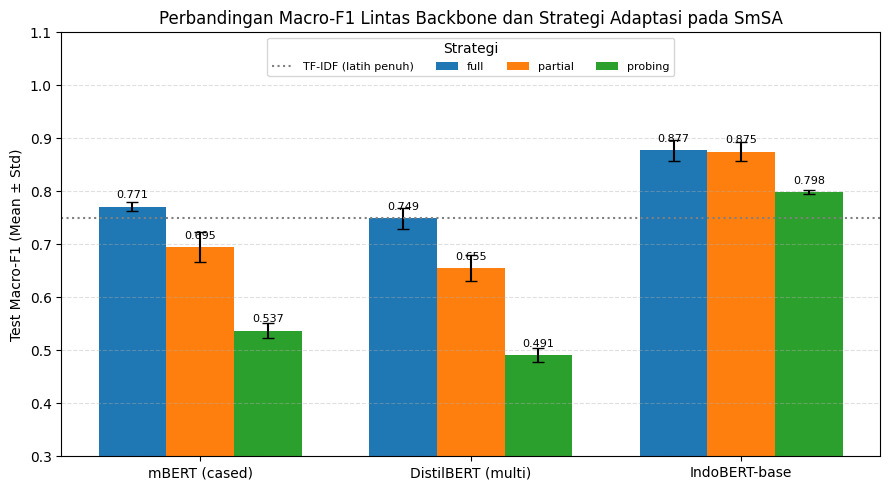

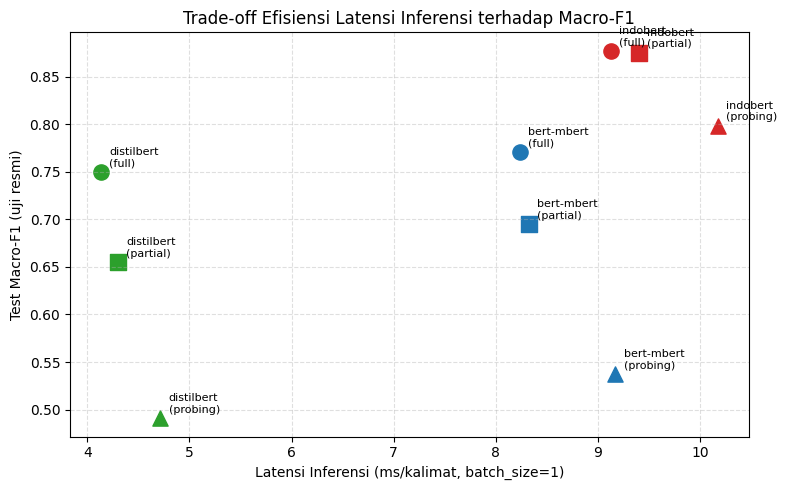

In [ ]:
import matplotlib.pyplot as plt

def fmt_mean_std(series, decimals=4):
    m = series.mean()
    s = series.std(ddof=1) if len(series) > 1 else 0.0
    return f"{m:.{decimals}f} ± {s:.{decimals}f}"

summary_rows = []
for b_key in ["bert-mbert", "distilbert", "indobert"]:
    for strat in ["full", "partial", "probing"]:
        sub = results_df[(results_df["backbone"] == b_key) & (results_df["strategy"] == strat)]
        if len(sub) == 0:
            continue
        summary_rows.append({
            "Backbone": b_key,
            "Strategi": strat,
            "Trainable Params": f"{int(sub['trainable_params'].iloc[0]):,}",
            "Accuracy (Mean±Std)": fmt_mean_std(sub["test_accuracy"], 4),
            "Macro-F1 (Mean±Std)": fmt_mean_std(sub["test_macro_f1"], 4),
            "F1 Negative": fmt_mean_std(sub["test_f1_negative"], 4),
            "F1 Neutral": fmt_mean_std(sub["test_f1_neutral"], 4),
            "F1 Positive": fmt_mean_std(sub["test_f1_positive"], 4),
            "Best Epoch (rata-rata)": f"{sub['best_epoch'].mean():.1f}",
            "Train Time (s)": fmt_mean_std(sub["train_time_sec"], 1),
            "Infer (ms/kalimat)": fmt_mean_std(sub["infer_ms_per_sent"], 2),
            "Peak Train VRAM (MB)": fmt_mean_std(sub["peak_train_mem_mb"], 0),
            "Total Params": f"{int(sub['total_params'].iloc[0]):,}",
        })

summary_table_df = pd.DataFrame(summary_rows)
REKAP_CSV = os.path.join(CONFIG["output_dir"], f"rekap_agregat_smsa_{RUN_CODE}.csv")
_m = ["test_accuracy","test_macro_f1","test_f1_negative","test_f1_neutral","test_f1_positive","val_macro_f1","best_epoch",
      "train_time_sec","infer_ms_per_sent","peak_train_mem_mb"]
_g = results_df.groupby(["backbone","strategy"])
rekap = _g[_m].agg(["mean","std"])
rekap.columns = [f"{a}_{b}" for a, b in rekap.columns]
rekap["n_seed"] = _g.size()
rekap["total_params"] = _g["total_params"].first()
rekap["trainable_params"] = _g["trainable_params"].first()
rekap.reset_index().to_csv(REKAP_CSV, index=False)
print("Tersimpan:", RESULTS_CSV, "|", REKAP_CSV)
display(summary_table_df)

# agregasi numerik untuk visualisasi
agg_num = (
    results_df.groupby(["backbone", "strategy"], as_index=False)
    .agg(
        f1_mean=("test_macro_f1", "mean"),
        f1_std=("test_macro_f1", "std"),
        neutral_mean=("test_f1_neutral", "mean"),
        infer_mean=("infer_ms_per_sent", "mean"),
        vram_mean=("peak_train_mem_mb", "mean"),
        time_mean=("train_time_sec", "mean"),
        trainable=("trainable_params", "first"),
    )
)

# grafik 1 perbandingan macro f1 antar backbone dan strategi
fig, ax = plt.subplots(figsize=(9, 5))
backbones_order = ["bert-mbert", "distilbert", "indobert"]
x = np.arange(len(backbones_order))
width = 0.25

for idx, strat in enumerate(["full", "partial", "probing"]):
    means = [
        agg_num[(agg_num["backbone"] == b) & (agg_num["strategy"] == strat)]["f1_mean"].values[0]
        for b in backbones_order
    ]
    stds = [
        agg_num[(agg_num["backbone"] == b) & (agg_num["strategy"] == strat)]["f1_std"].values[0]
        for b in backbones_order
    ]
    bars = ax.bar(x + (idx - 1) * width, means, width, yerr=stds, capsize=4, label=strat)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, m + 0.012, f"{m:.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(["mBERT (cased)", "DistilBERT (multi)", "IndoBERT-base"])
ax.set_ylabel("Test Macro-F1 (Mean ± Std)")
ax.set_title("Perbandingan Macro-F1 Lintas Backbone dan Strategi Adaptasi pada SmSA")
ax.set_ylim(0.3, 1.1)
if "baseline_df" in globals():                       # garis pembanding baseline TF-IDF (uji resmi)
    ax.axhline(float(baseline_df["test_macro_f1"].iloc[1]), color="gray", linestyle=":", linewidth=1.5, label="TF-IDF (latih penuh)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="Strategi", loc="upper center", ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "grafik_perbandingan_f1.png"), dpi=300)
plt.show()

# grafik 2 tradeoff latensi inferensi vs macro f1
fig, ax = plt.subplots(figsize=(8, 5))
markers = {"full": "o", "partial": "s", "probing": "^"}
colors = {"bert-mbert": "#1f77b4", "distilbert": "#2ca02c", "indobert": "#d62728"}

for _, row in agg_num.iterrows():
    ax.scatter(
        row["infer_mean"],
        row["f1_mean"],
        s=120,
        marker=markers[row["strategy"]],
        color=colors[row["backbone"]],
        label=f"{row['backbone']} - {row['strategy']}",
    )
    ax.annotate(
        f"{row['backbone']}\n({row['strategy']})",
        (row["infer_mean"], row["f1_mean"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )

ax.set_xlabel("Latensi Inferensi (ms/kalimat, batch_size=1)")
ax.set_ylabel("Test Macro-F1 (uji resmi)")
ax.set_title("Trade-off Efisiensi Latensi Inferensi terhadap Macro-F1")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "grafik_tradeoff_latensi.png"), dpi=300)
plt.show()

- IndoBERT menghasilkan F1 makro tertinggi pada ketiga strategi. Jika dibandingkan dengan baseline TF-IDF (0,750), hanya IndoBERT dan mBERT full yang berada di atasnya. Hasil IndoBERT full dan partial memiliki rentang simpangan baku yang saling tumpang tindih, sehingga performanya belum dapat dibedakan secara jelas. Artinya, partial freezing berpotensi memberikan hasil setara dengan full fine-tuning dengan biaya lebih rendah

- DistilBERT memiliki latensi terendah, sekitar 4 ms, tetapi F1 makronya juga lebih rendah. IndoBERT full dan partial menghasilkan F1 tertinggi dengan latensi sekitar 8 ms. mBERT dan IndoBERT memiliki latensi yang hampir sama karena jumlah lapis arsitekturnya sama. Grafik menunjukkan bahwa strategi fine-tuning memengaruhi F1, tetapi tidak banyak mengubah latensi inferensi.

### 7.2 Efisiensi dan Kebermaknaan Selisih
Selisih F1 makro antara dua sel dianggap **bermakna** bila lebih besar dari simpangan antar-seed terbesar di antara keduanya (aturan soal); bila lebih kecil, dianggap belum berbeda.

In [ ]:
tfidf_f1 = float(baseline_df["test_macro_f1"].iloc[1])
agg = results_df.groupby(["backbone", "strategy"]).agg(
    f1=("test_macro_f1", "mean"), sd=("test_macro_f1", "std"),
    waktu=("train_time_sec", "mean"), vram=("peak_train_mem_mb", "mean"),
    infer=("infer_ms_per_sent", "mean"), params=("total_params", "first"),
)
agg["f1_minus_tfidf"] = agg["f1"] - tfidf_f1

# q1: perbandingan backbone pada full fine-tuning
print("Q1 - full fine-tuning per backbone")
display(agg.xs("full", level="strategy").round(4))

# q2: strategi hemat vs full; bermakna bila selisih > sd terbesar kedua sel
rows = []
for b in agg.index.get_level_values("backbone").unique():
    full = agg.loc[(b, "full")]
    for s in ("partial", "probing"):
        r = agg.loc[(b, s)]
        delta, sd_max = full["f1"] - r["f1"], max(full["sd"], r["sd"])
        rows.append({
            "backbone": b, "strategi": s, "selisih_f1": delta, "sd_maks": sd_max,
            "selisih/sd": delta / sd_max,
            "hemat_waktu_%": (1 - r["waktu"] / full["waktu"]) * 100,
            "hemat_vram_%": (1 - r["vram"] / full["vram"]) * 100,
            "bermakna": "ya" if delta > sd_max else "belum beda",
        })
print("Q2 - strategi hemat komputasi terhadap full fine-tuning")
display(pd.DataFrame(rows).round(3))

Q1 - full fine-tuning per backbone


,f1,sd,waktu,vram,infer,params,f1_minus_tfidf
backbone,,,,,,,
bert-mbert,0.7707,0.0083,176.5164,4217.6370,8.2364,177265155,0.0207
distilbert,0.7493,0.0200,101.7872,2948.1024,4.1327,134736387,-0.0007
indobert,0.8771,0.0192,131.6210,3321.5454,9.1236,123853059,0.1271


Q2 - strategi hemat komputasi terhadap full fine-tuning


,backbone,strategi,selisih_f1,sd_maks,selisih/sd,hemat_waktu_%,hemat_vram_%,bermakna
0,bert-mbert,partial,0.076,0.029,2.637,46.388,45.858,ya
1,bert-mbert,probing,0.233,0.015,15.969,74.015,71.399,ya
2,distilbert,partial,0.095,0.024,3.890,54.214,48.910,ya
3,distilbert,probing,0.258,0.020,12.886,77.194,65.114,ya
4,indobert,partial,0.002,0.019,0.115,41.768,41.654,belum beda
5,indobert,probing,0.079,0.019,4.107,72.751,70.931,ya


### 7.3 Uji Sensitivitas Linear Probing
Skor probing mBERT dan DistilBERT berada di bawah baseline TF-IDF (0,750), dan *training loss* masih turun pada epoch terakhir. Sel berikut menguji dua penyebab yang mungkin pada mBERT (seed 42) dengan **F1 makro validasi saja** (data uji tidak disentuh): nilai learning rate dan dropout pada backbone beku (mode `train` vs `eval`). Baris pertama (`2e-3`, `train`) harus mereproduksi F1 validasi run utama (≈ 0,719).

In [ ]:
def probe_check(backbone_key, lr, backbone_eval, seed=42, epochs=5):
    # latih linear probing dan kembalikan f1 makro validasi terbaik (uji tidak disentuh)
    seed_everything(seed)
    dl_tr, dl_va, _ = make_loaders(backbone_key, seed)
    model = build_model(backbone_key, "probing", seed)
    optimizer, scheduler = build_optimizer_and_scheduler(model, lr, len(dl_tr) * epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_FP16)
    best_f1 = 0.0
    for _ in range(epochs):
        model.train()
        if backbone_eval:
            model.backbone.eval()      # matikan dropout pada backbone beku
        for batch in dl_tr:
            labels = batch["labels"].to(DEVICE)
            inputs = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=USE_FP16):
                loss = criterion(model(**inputs), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        best_f1 = max(best_f1, evaluate_predictions(model, dl_va)["macro_f1"])
    del model, optimizer, scheduler, scaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return best_f1

probe_rows = []
for lr in (2e-3, 1e-2, 5e-2):
    for be in (False, True):
        f1_val = probe_check("bert-mbert", lr, be)
        probe_rows.append({"lr": lr, "backbone_mode": "eval" if be else "train", "val_macro_f1": round(f1_val, 4)})
display(pd.DataFrame(probe_rows))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,lr,backbone_mode,val_macro_f1
0,0.002,train,0.7193
1,0.002,eval,0.7253
2,0.010,train,0.7476
3,0.010,eval,0.7605
4,0.050,train,0.7455
5,0.050,eval,0.7426


## 8. Pembahasan

Seluruh hasil pada bagian ini menggunakan metrik pengujian terhadap 500 kalimat, dengan nilai rata-rata (*mean*) ± simpangan baku (SD) dari 3 seed. Sebagai pembanding, model TF-IDF + Logistic Regression (LR) menghasilkan F1 makro sebesar 0,750, sedangkan tebakan acak menghasilkan skor sekitar 0,33.

### 8.1 Evaluasi Hipotesis

- **H1 (didukung).** IndoBERT dengan *full fine-tuning* memperoleh F1 makro tertinggi, yaitu 0,877 ± 0,019. Nilai ini lebih tinggi 0,106 dibandingkan mBERT (0,771 ± 0,008) dan 0,128 dibandingkan DistilBERT (0,749 ± 0,020). Keunggulan IndoBERT juga terlihat pada kelas `neutral`, dengan F1 sebesar 0,76, sedangkan mBERT dan DistilBERT masing-masing memperoleh 0,62 dan 0,60. Hasil ini menunjukkan bahwa IndoBERT memberikan performa terbaik pada dataset yang digunakan.

- **H2 (sebagian didukung).** Urutan performa *full fine-tuning* ≥ *partial freezing* > *linear probing* terlihat pada ketiga backbone. Namun, pada IndoBERT, selisih F1 antara *full fine-tuning* dan *partial freezing* hanya 0,002, lebih kecil daripada SD sebesar 0,019. Dengan demikian, berdasarkan kriteria operasional penelitian, keduanya belum menunjukkan perbedaan yang berarti. Penurunan F1 pada *linear probing* IndoBERT (−0,079) juga lebih kecil dibandingkan mBERT (−0,233) dan DistilBERT (−0,258). Hasil ini menunjukkan bahwa dampak strategi adaptasi bergantung pada backbone yang digunakan, sejalan dengan pembahasan Peters dkk. (2019).

- **H3 (sebagian didukung).** Dibandingkan mBERT, DistilBERT memiliki latensi sekitar 50% lebih rendah (4,13 vs 8,24 ms), waktu latih 42% lebih singkat, penggunaan VRAM 30% lebih rendah, dan jumlah parameter 24% lebih sedikit. Pengurangan parameter tidak mencapai 40% karena ukuran matriks embedding multibahasa turut memengaruhi jumlah parameter model. Namun, F1 DistilBERT lebih rendah 0,021 dibandingkan mBERT. Jika dibandingkan dengan IndoBERT, DistilBERT memiliki selisih F1 sebesar 0,128. Skornya juga hampir sama dengan TF-IDF + LR (0,749 vs 0,750). Dengan demikian, efisiensi DistilBERT perlu dipertimbangkan bersama penurunan performanya.

### 8.2 Jawaban Pertanyaan Riset

**Q1 — Backbone dengan trade-off terbaik: IndoBERT.**

| Backbone (full) | F1 Makro | Waktu Latih | Latensi | Parameter |
| :--- | :---: | :---: | :---: | :---: |
| IndoBERT | **0,877 ± 0,019** | 131,6 s | 9,12 ± 1,58 ms | **123,9 jt** |
| mBERT | 0,771 ± 0,008 | 176,5 s | 8,24 ± 0,11 ms | 177,3 jt |
| DistilBERT | 0,749 ± 0,020 | **101,8 s** | **4,13 ± 0,04 ms** | 134,7 jt |

IndoBERT memberikan performa terbaik berdasarkan F1 makro dan memiliki jumlah parameter paling sedikit di antara ketiga backbone. Waktu latihnya juga 25% lebih singkat dibandingkan mBERT. Sementara itu, latensi IndoBERT dan mBERT relatif berdekatan, meskipun hasil pengukuran IndoBERT memiliki variasi yang lebih besar. DistilBERT unggul dalam kecepatan inferensi dan waktu pelatihan, tetapi menghasilkan F1 makro yang lebih rendah.

**Q2 — Efisiensi komputasi bergantung pada backbone yang digunakan.**

Pada IndoBERT, *partial freezing* menghasilkan F1 makro sebesar 0,875, hanya berbeda 0,002 dari *full fine-tuning*. Berdasarkan kriteria operasional penelitian, keduanya belum menunjukkan perbedaan yang berarti. Strategi ini juga menghemat waktu latih sebesar 42% dan penggunaan VRAM sebesar 42%.

Sebaliknya, *linear probing* pada IndoBERT menurunkan F1 sebesar 0,079, meskipun mampu menghemat waktu latih sekitar 73%. Pada mBERT dan DistilBERT, *partial freezing* menurunkan F1 masing-masing sebesar 0,076 dan 0,095, sedangkan *linear probing* menurunkan F1 sebesar 0,233 dan 0,258. Berdasarkan aturan operasional pada bagian 7.2, penurunan tersebut termasuk berarti karena selisihnya lebih besar daripada SD pembanding.

Dengan demikian, *partial freezing* menjadi strategi yang paling kompetitif pada IndoBERT, sedangkan penghematan komputasi pada mBERT dan DistilBERT disertai penurunan performa yang lebih besar. Rincian perbandingan selisih F1 dan SD dapat dilihat pada tabel bagian 7.2.

**Q3 — Rekomendasi: IndoBERT + partial freezing (6 dari 12 lapisan awal dibekukan).**

Berdasarkan kriteria pemilihan pada bagian 1.5, kombinasi IndoBERT dengan *partial freezing* menjadi rekomendasi utama karena:

1. Menghasilkan F1 makro sebesar 0,875, lebih tinggi dibandingkan TF-IDF + LR (0,750).
2. Memiliki performa yang sangat dekat dengan IndoBERT *full fine-tuning* (0,877).
3. Lebih hemat komputasi dibandingkan *full fine-tuning*, dengan waktu latih 76,6 detik dan penggunaan VRAM 1.938 MB. Keduanya berkurang sekitar 42%.
4. Seluruh hasil didasarkan pada pengujian dengan konfigurasi dan metrik yang sama dalam eksperimen ini.

Latensi IndoBERT *partial freezing* sebesar 9,40 ± 1,46 ms juga relatif dekat dengan hasil *full fine-tuning*. Namun, jika kebutuhan sistem menetapkan latensi sekitar 4 ms sebagai batas mutlak, DistilBERT menjadi Transformer tercepat dalam eksperimen ini, meskipun F1-nya hampir sama dengan TF-IDF + LR. Oleh karena itu, TF-IDF + LR dapat dipertimbangkan sebagai alternatif yang lebih sederhana.

### 8.3 Keterbatasan

1. **Ukuran data uji terbatas.** Pengujian hanya menggunakan 500 kalimat, dengan 88 kalimat pada kelas `neutral`. Jumlah tersebut membatasi cakupan evaluasi, terutama untuk menilai performa model pada kelas dengan jumlah data yang lebih sedikit.

2. **Jumlah seed terbatas.** Eksperimen hanya menggunakan 3 seed sehingga SD yang diperoleh belum tentu menggambarkan seluruh variasi hasil pelatihan. Selain itu, penelitian ini tidak melakukan uji signifikansi statistik formal. Penilaian perbedaan performa menggunakan aturan operasional berupa perbandingan selisih F1 dengan SD, sehingga hasilnya perlu ditafsirkan secara hati-hati.

3. **Konfigurasi linear probing terbatas.** Eksperimen utama menggunakan satu nilai learning rate (`2e-3`) dan backbone beku berada pada mode `train`. Uji sensitivitas pada mBERT (seed 42, bagian 7.3) menunjukkan bahwa perubahan learning rate dapat meningkatkan F1 validasi dari 0,719 hingga 0,761 pada learning rate `1e-2`. Namun, nilai tersebut masih di bawah TF-IDF + LR pada validasi (0,828). Karena pengujian sensitivitas hanya dilakukan pada satu seed dan satu backbone, hasilnya belum cukup untuk menyimpulkan konfigurasi terbaik bagi seluruh model. Oleh sebab itu, performa *linear probing* masih berpotensi meningkat melalui penyesuaian konfigurasi.

4. **Cakupan eksperimen terbatas.** Penelitian menggunakan satu subset data latih sebanyak 5.000 kalimat dengan `seed = 42`, satu dataset, dan pengukuran latensi pada satu GPU Tesla T4. Kondisi tersebut membatasi generalisasi hasil, terutama karena latensi dapat dipengaruhi oleh perangkat keras dan kondisi pengukuran. Selain itu, pelatihan hanya dilakukan selama 5 epoch sehingga belum dapat dipastikan apakah seluruh konfigurasi telah mencapai performa optimal.

5. **Bukan replikasi langsung IndoNLU.** Hasil penelitian tidak dapat dibandingkan secara langsung dengan hasil paper IndoNLU karena terdapat perbedaan konfigurasi eksperimen, seperti `batch size` 16, pencarian learning rate, dan jumlah epoch yang digunakan dalam penelitian tersebut.

---

### 8.4 Daftar Pustaka

1. Ben-Zaken, E., Goldberg, Y., & Ravfogel, S. (2022). BitFit: Simple Parameter-efficient Fine-tuning for Transformer-based Masked Language-models. *Proceedings of the 60th Annual Meeting of the Association for Computational Linguistics (Volume 2: Short Papers)*, 1–9. https://doi.org/10.18653/v1/2022.acl-short.1

2. Kim, Y. J., & Awadalla, H. H. (2020). FastFormers: Highly Efficient Transformer Models for Natural Language Understanding. *Proceedings of SustaiNLP: Workshop on Simple and Efficient Natural Language Processing*, 149–158. https://doi.org/10.18653/v1/2020.sustainlp-1.20

3. Mosbach, M., Andriushchenko, M., & Klakow, D. (2021). On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines. *International Conference on Learning Representations (ICLR 2021)*. https://openreview.net/forum?id=nzpLWnVAyah

4. Peters, M. E., Ruder, S., & Smith, N. A. (2019). To Tune or Not to Tune? Adapting Pretrained Representations to Diverse Tasks. *Proceedings of the 4th Workshop on Representation Learning for NLP (RepL4NLP-2019)*, 7–14. https://doi.org/10.18653/v1/W19-4302

5. Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter. *arXiv preprint arXiv:1910.01108*.

6. Wilie, B., Vincentio, K., Winata, G. I., Cahyawijaya, S., Li, X., Lim, Z. Y., Soleman, S., Mahendra, R., Fung, P., Bahar, S., & Purwarianti, A. (2020). IndoNLU: Benchmark and Resources for Evaluating Indonesian Natural Language Understanding. *Proceedings of the 1st Conference of the Asia-Pacific Chapter of the Association for Computational Linguistics and the 10th International Joint Conference on Natural Language Processing (AACL-IJCNLP 2020)*, 843–857. https://aclanthology.org/2020.aacl-main.85/

7. Zhang, T., Wu, F., Katiyar, A., Weinberger, K. Q., & Artzi, Y. (2021). Revisiting Few-sample BERT Fine-tuning. *International Conference on Learning Representations (ICLR 2021)*. https://openreview.net/forum?id=cO1IH43yUF